#### In this notebook, we use a Neural ODE to learn a dynamical system from data. 


We generate the data in this notebook itself. For data generation, consider a simple ODE for the first-order decay of a molecule:
$$\frac{dx}{dt}=-kx$$

Now, assume that we do not know the model. We only have the data. Our proposed model is:
$$\frac{dx}{dt}=N_{\theta}(x)$$

Here, $N_{\theta}(x)$ is the neural network with parameter $\theta$. We will use the Neural ODE algorithm to learn $N_{\theta}(x)$ from the data. Subsequently, will compare the data predicted by the learned neural ODE model and the real model $\frac{dx}{dt}=-kx$.

The SciML (Scientific Machine Learning) ecosystem in Julia has several packages for neural ODEs. For example, `DiffEqFlux.jl`, `Lux.jl`, `Zygote`, etc. However, in this notebook, we do not use these packages. Rather, we use simple Julia code so that you can understand the algorithm of neural ODEs.


#### Install packages

This notebook uses the following Julia packages:


`Plots`: For plotting data.


`Random`: For random number generation.


`ForwardDiff`: For calculating the gradient of the loss function.

`Optimizers`: To update parameters using Adam, a gradient-based optimization algorithm.

`DifferentialEquations.jl`: To solve neural ODEs, just like a standard ODE.

Install these packages before using this notebook:

`you@you:~$ julia`


`julia> using Pkg`


`julia> Pkg.add("ForwardDiff")`

In [1]:
# 1. Load the Packages

using Plots, Random, ForwardDiff, Optimisers, DifferentialEquations

#### Generation of synthetic data
We generate the data for model building in this notebook itself using the ODE: $\frac{dx}{dt}=-kx$. By solving this ODE, we get $x = x_{0}e^{-kt}$. This equation is used to generate data.

Specify the numerical values for the following parameters:


`t_0`: Initial time (default is zero)

`t_final`: Final time

`Δ`: Increment in time

`k`: Rate constant

`x0`: Initial value of x.

`η`: Noise strength ($\ge 0$); better set it to zero initially.

**Note**: You can use symbols like $\eta$, $\Delta$, in a Julia code.

In [2]:
# 2. User inputs for data generation
# Specify the numerical values of the following parameters

t_0 = 0.0
t_final = 3.0
Δ = 0.1

k = 0.8

x0 = 1.0

η = 0.02


0.02

In [3]:
# 3. Generate synthetic data

# Generate time points
times = collect(t_0 : Δ : t_final)

# Generate values of x for the time points
# We are using the equation: x = x0*exp(-k*t) + Noise
# The noise term is added to add deviation from exact data

data = x0 .* exp.(-k .* times) + η .* rand(length(times));

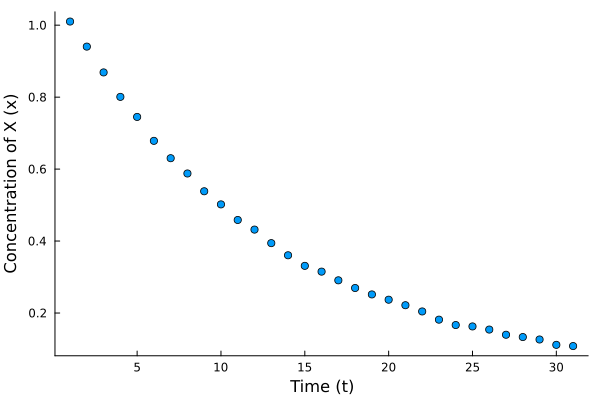

In [4]:
# 4. Plot the synthetic data
scatter(data,
        xlabel = "Time (t)", 
        ylabel = "Concentration of X (x)",
        legend = false,
        grid = false)

#### The main scheme
We will use a neural network to represent the right-hand side of our ODE:
$$\frac{dx}{dt}=N_{\theta}\left( x \right)$$

We use a small network with one input, four hidden neurons, and one output:
$$N_\theta(x)=c+\sum_{j=1}^{4}v_j\tanh(w_jx+b_j)$$

Here, $b$ and $c$ are biases. $w$ and $v$ are weights. We will learn these parameters from the data. 

Our algorithm has the following sequence:
1. We first define several helper functions: `neural_rate()`, `predict()`, and `loss()`. 
2. Then we define the main function `train()`. This function uses the helper functions to train our neural ODE on the given data.

In the subsequent sections, we explain the key elements of each of these functions.


#### Inputs for the NN
Specify the numerical values for the following parameters for the neural ODE:

`H`: Number of hidden node (set to 4, as we want a four node NN)

`iterations`: Number of iterations for learning the parameters


`learning_rate`: the learning rate


In [5]:
# 6. Input parameters for the neural network model

H = 4  # Do not change this 

iterations = 20000

learning_rate = 0.01

0.01

#### The neural_rate() function

We first define the neural network using the function `neural_rate()`. Essentially, this is the RHS of our neural ODE: $\frac{dx}{dt}=N_{\theta}\left( x \right)$.

In [6]:
# 7. The neural network is defined here through this function

# 1 input -> 4 hidden neurons -> 1 output
# Input: x
# Output: predicted dx/dt

# Function arguments
# x: Value of x
# p: Vector storing neural network parameters

function neural_rate(x, p)

    # Input weights
    w1, w2, w3, w4 = p[1:4]

    # Hidden neuron biases
    b1, b2, b3, b4 = p[5:8]

    # Output weights
    v1, v2, v3, v4 = p[9:12]

    # Output bias
    c = p[13]

    # Hidden nodes: weighted input followed by activation
    h1 = tanh(w1*x + b1)
    h2 = tanh(w2*x + b2)
    h3 = tanh(w3*x + b3)
    h4 = tanh(w4*x + b4)

    # Combine hidden neuron outputs to predict the rate
    dxdt = v1*h1 + v2*h2 + v3*h3 + v4*h4 + c

    return dxdt
end

neural_rate (generic function with 1 method)

#### The predict() function
`predict()` is a fucntion to solve $\frac{dx}{dt}=N_{\theta}\left( x \right)$ using the fifth-order Runge-Kutta method (RK4). This function is used to predict the x vs. t data for a given initial value of x.
  
   We use `solve()` from the `DifferentialEquations` package, which is used to numerically solve a system of ODEs. To solve a system of ODEs, we have to first define the ODE problem. Suppose we are solving the ODE $\frac{dx}{dt}=-kx$. The ODE problem can be defined using the function `ODEProblem()`:

   ``` julia
   problem = ODEProblem(
                (x, k, t) -> -k*x,     # anonymus function for ODE
                u0,                    # Initial value
                (first(ts), last(ts)), # Time span
                k                      # Parameter value
                )
```
Then we solve this ODE problem using `solve()`:
   ``` julia
    solution = solve(
                problem, Tsit5();
                saveat=ts,
                abstol=1e-7,
                reltol=1e-7
                )
```
   

   For solving our neural ODE, we simply replace `(x, k, t) -> -k*x` with an anonymous function for our neural ODE: `(x, p, t) -> neural_rate(x, p)`.


In [7]:
# 8. This function solves dx/dt = neural_rate(x,p), 
# using the fifth-order explicit Runge–Kutta method.

# Arguments for this function
# p: Parameters
# initial: Initial value of x
# ts: The time points

# This function returns the values of x
# at time points in the training data

function predict(p; initial=x0, ts=times)

    # Get the initial value as a float
    u0 = convert(eltype(p), initial)

    # Define the ODE problem
    problem = ODEProblem(
                (x, p, t) -> neural_rate(x, p),
                u0,
                (first(ts), last(ts)),
                p)

    # Solve the ODE problem
    solution = solve(problem, Tsit5();
                    saveat=ts, # save data at specific time points
                    abstol=1e-7,
                    reltol=1e-7
                    )

    # Return values of x
    return solution.u
end

predict (generic function with 1 method)

#### The loss() function
The loss function `loss()` essentially gives the mean squared error (MSE):
$$L(\mathbf{p}) = \frac{1}{n} \sum_{i=1}^{n}\left[\widehat{x}(t_i;\mathbf{p}) - x_i\right]^2$$

Here,

$\mathbf{p}$: Neural-network parameter set.

$\widehat{x}(t_i;\mathbf{p})$: Value of $x$ predicted by neural ODE for time $t_{i}$.

$x_{i}$: Observed value at time $t_{i}$.

$n$: number of observations.

During training, we use a gradient-based method to minimize $L$.


In [8]:
# 9. Define the loss function
loss(p) = sum(abs2, predict(p) .- data) / length(data)

loss (generic function with 1 method)

#### The train() function
`train()` is the main function for training the neural ODE. It uses an iterative training method. Starting from random parameter values, each iteration performs three steps:
1. Predict and compare: Solve the neural ODE using the current parameters. Compare the predicted $x$ vs $t$ data with the training data to calculate the loss $L(\mathbf p)$.
2. Calculate gradients: Determine how the loss responds to a small change in each parameter:
$$g_{j}=\frac{\partial L}{\partial p_{j}}$$
   A positive gradient means increasing that parameter locally increases the loss. A negative gradient means increasing it locally decreases the loss.
3. Update the parameters: Move the parameters in a direction intended to reduce the loss. In basic gradient descent:
$$p_{j}\leftarrow p_{j}-\alpha g_{j}$$

   where $\alpha$ is the learning rate. Our code uses the Adam algorithm, which modifies this update using the history and magnitude of the gradients.
   
The next iteration solves the ODE again with the updated parameters. This cycle continues until the chosen number of iterations is completed.

The aim is to find parameters that produce a trajectory close to the observations. 

In [9]:
# 10. The main function to train the neural network

function train()

    # Set the seed of the random number generator
    # for reproducible result
    Random.seed!(42)

    # Generate the initial random parameter
    # values
    p = 0.2 .* randn(3H+1)  # In Julia 3H is same as 3*H

    # Calculate the Mean Squared Error (MSE)
    # for the initial parameter values
    initial_mse = loss(p)

    # Initialize Adam and its internal memory once
    optimizer = Optimisers.Adam(learning_rate)
    state = Optimisers.setup(optimizer, p)

    # Initialize the vector to store the loss gradient
    g = zeros(length(p))

    # Iteratively find the best parameter set (p)
    for epoch in 1:iterations

        # Calculate gradients using automatic differentiation
        ForwardDiff.gradient!(g, loss, p)

        # Update parameters using Adam
        state, p = Optimisers.update(state, p, g)
    end

    # Predict data using the final model
    predicted_x = predict(p)

    # Calculate the error in the final model
    final_mse = sum(abs2, predicted_x .- data) / length(data)

    return p, predicted_x, initial_mse, final_mse
end

train (generic function with 1 method)

#### Train the neural ODE
The required functions are already defined. Now we call the `train()` function to train our neural ODE on the data.

In [10]:
# 11. Train the neural network
n_ode = train()

println("Training is over. Compare initial and final MSE.", "\n")
println("Initial MSE: ", n_ode[3], "\n")
println("Final MSE: ", n_ode[4], "\n")

Training is over. Compare initial and final MSE.

Initial MSE: 0.09133006436232861

Final MSE: 1.9178760367682336e-5



#### Plot and compare neural ODE data with the original data

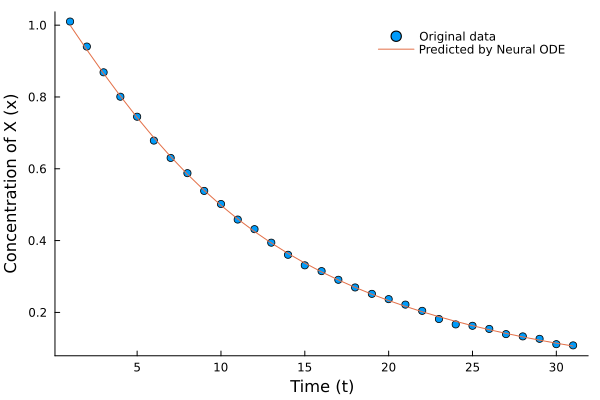

In [11]:
# 12. Plot the original data points and overlay the
# data predicted by the learned neural ODE.

scatter(data,
        xlabel = "Time (t)",
        ylabel = "Concentration of X (x)",
        label = "Original data",
        fg_legend = :transparent,
        grid = false)

plot!(n_ode[2],
    label = "Predicted by Neural ODE")

#### Try the trained neural ODE for a new initial value
Now we use the trained neural ODE to make a prediction. We specify a new initial value of x and predict the dynamics. 

Specify `new_x0`, the new initial value of x.

In [12]:
# 14. Input for new initial value

new_x0 = 0.5

0.5

In [13]:
# 15. Make the prediction

# Get the learned parameter values 
# from the model
trained_p = n_ode[1]

# Make prediction
new_predicted = predict(trained_p; initial= new_x0);

In [14]:
# 16. Expected behavior for the same initial condition
# We need this for comparison with the prediction

new_data = new_x0 .* exp.(-k .* times);

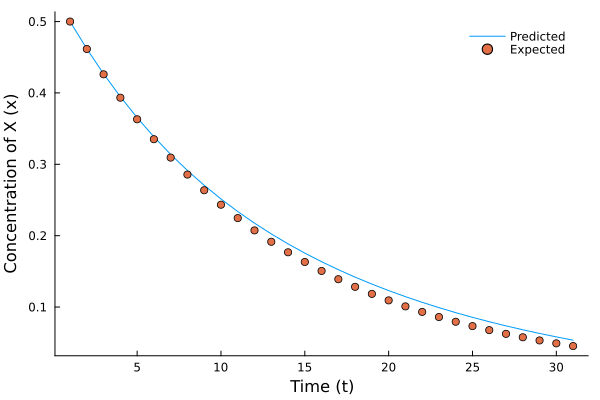

In [15]:
# Plot the predicted and expected data

plot(new_predicted,
    xlabel = "Time (t)",
    ylabel = "Concentration of X (x)",
    label = "Predicted",
    fg_legend = :transparent,
    grid = false)

scatter!(new_data,
    label = "Expected")